<a href="https://colab.research.google.com/github/ChetanAnandN/adaptive-graph-rag/blob/main/HotpotQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install pandas pyarrow

In [4]:
from google.colab import files

uploaded = files.upload()

Saving validation-00000-of-00001.parquet to validation-00000-of-00001.parquet


In [5]:
import pandas as pd

df = pd.read_parquet("validation-00000-of-00001.parquet")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (7405, 7)
Columns: ['id', 'question', 'answer', 'type', 'level', 'supporting_facts', 'context']


In [6]:
data = df.head(100).copy()

print("Total selected records:", len(data))

Total selected records: 100


In [7]:
print("QUESTION:")
print(data.iloc[0]["question"])

print("\nANSWER:")
print(data.iloc[0]["answer"])

print("\nTYPE:")
print(data.iloc[0]["type"])

print("\nLEVEL:")
print(data.iloc[0]["level"])

print("\nCONTEXT:")
print(data.iloc[0]["context"])

print("\nSUPPORTING FACTS:")
print(data.iloc[0]["supporting_facts"])

QUESTION:
Were Scott Derrickson and Ed Wood of the same nationality?

ANSWER:
yes

TYPE:
comparison

LEVEL:
hard

CONTEXT:
{'title': array(['Ed Wood (film)', 'Scott Derrickson', 'Woodson, Arkansas',
       'Tyler Bates', 'Ed Wood', 'Deliver Us from Evil (2014 film)',
       'Adam Collis', 'Sinister (film)', 'Conrad Brooks',
       'Doctor Strange (2016 film)'], dtype=object), 'sentences': array([array(['Ed Wood is a 1994 American biographical period comedy-drama film directed and produced by Tim Burton, and starring Johnny Depp as cult filmmaker Ed Wood.',
              " The film concerns the period in Wood's life when he made his best-known films as well as his relationship with actor Bela Lugosi, played by Martin Landau.",
              ' Sarah Jessica Parker, Patricia Arquette, Jeffrey Jones, Lisa Marie, and Bill Murray are among the supporting cast.'],
             dtype=object)                                                                                                        

In [8]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
id                  0
question            0
answer              0
type                0
level               0
supporting_facts    0
context             0
dtype: int64


In [9]:
import re

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

data["clean_question"] = data["question"].apply(clean_text)
data["clean_answer"] = data["answer"].apply(clean_text)

print("Text cleaning completed!")

display(data[[
    "question",
    "clean_question",
    "answer",
    "clean_answer"
]].head())

Text cleaning completed!


,question,clean_question,answer,clean_answer
0,Were Scott Derrickson and Ed Wood of the same ...,Were Scott Derrickson and Ed Wood of the same ...,yes,yes
1,What government position was held by the woman...,What government position was held by the woman...,Chief of Protocol,Chief of Protocol
2,"What science fantasy young adult series, told ...","What science fantasy young adult series, told ...",Animorphs,Animorphs
3,Are the Laleli Mosque and Esma Sultan Mansion ...,Are the Laleli Mosque and Esma Sultan Mansion ...,no,no
4,"The director of the romantic comedy ""Big Stone...","The director of the romantic comedy ""Big Stone...","Greenwich Village, New York City","Greenwich Village, New York City"


In [10]:
documents = []

for _, row in data.iterrows():
    titles = row["context"]["title"]
    sentences = row["context"]["sentences"]

    for title, paragraph in zip(titles, sentences):
        text = " ".join(str(sentence) for sentence in paragraph)

        documents.append({
            "question_id": row["id"],
            "title": title,
            "text": clean_text(text)
        })

corpus = pd.DataFrame(documents)

print("Corpus preparation completed!")
print("Total documents:", len(corpus))

display(corpus.head())

Corpus preparation completed!
Total documents: 992


,question_id,title,text
0,5a8b57f25542995d1e6f1371,Ed Wood (film),Ed Wood is a 1994 American biographical period...
1,5a8b57f25542995d1e6f1371,Scott Derrickson,"Scott Derrickson (born July 16, 1966) is an Am..."
2,5a8b57f25542995d1e6f1371,"Woodson, Arkansas",Woodson is a census-designated place (CDP) in ...
3,5a8b57f25542995d1e6f1371,Tyler Bates,"Tyler Bates (born June 5, 1965) is an American..."
4,5a8b57f25542995d1e6f1371,Ed Wood,"Edward Davis Wood Jr. (October 10, 1924 – Dece..."


In [11]:
!pip install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 23.9 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [12]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy model loaded successfully!")

spaCy model loaded successfully!


In [13]:
text = """
Scott Derrickson is an American director.
Ed Wood was an American filmmaker.
"""

doc = nlp(text)

for ent in doc.ents:
    print(ent.text, "->", ent.label_)

Scott Derrickson -> PERSON
American -> NORP
Ed Wood -> PERSON
American -> NORP


In [14]:
entities = []

for _, row in corpus.iterrows():
    doc = nlp(row["text"])

    for ent in doc.ents:
        entities.append({
            "entity": ent.text,
            "entity_type": ent.label_,
            "source_title": row["title"],
            "question_id": row["question_id"]
        })

entities_df = pd.DataFrame(entities)

print("Entity extraction completed!")
print("Total entity mentions:", len(entities_df))

display(entities_df.head(10))

Entity extraction completed!
Total entity mentions: 14391


,entity,entity_type,source_title,question_id
0,Ed Wood,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371
1,1994,DATE,Ed Wood (film),5a8b57f25542995d1e6f1371
2,American,NORP,Ed Wood (film),5a8b57f25542995d1e6f1371
3,Tim Burton,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371
4,Johnny Depp,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371
5,Ed Wood,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371
6,Wood,ORG,Ed Wood (film),5a8b57f25542995d1e6f1371
7,Bela Lugosi,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371
8,Martin Landau,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371
9,Sarah Jessica Parker,PERSON,Ed Wood (film),5a8b57f25542995d1e6f1371


In [15]:
unique_entities = entities_df[["entity", "entity_type"]].drop_duplicates()

print("Total entity mentions:", len(entities_df))
print("Total unique entities:", len(unique_entities))

print("\nEntity type distribution:")
print(unique_entities["entity_type"].value_counts())

display(unique_entities.head(15))

Total entity mentions: 14391
Total unique entities: 8332

Entity type distribution:
entity_type
ORG            2246
PERSON         2101
DATE           1278
GPE             802
WORK_OF_ART     559
CARDINAL        383
NORP            204
FAC             171
LOC             170
EVENT           104
QUANTITY         71
PRODUCT          66
ORDINAL          65
MONEY            37
LAW              26
PERCENT          23
TIME             19
LANGUAGE          7
Name: count, dtype: int64


,entity,entity_type
0,Ed Wood,PERSON
1,1994,DATE
2,American,NORP
3,Tim Burton,PERSON
4,Johnny Depp,PERSON
6,Wood,ORG
7,Bela Lugosi,PERSON
8,Martin Landau,PERSON
9,Sarah Jessica Parker,PERSON
10,Patricia Arquette,PERSON


In [16]:
import networkx as nx
from itertools import combinations

G = nx.Graph()

for _, row in corpus.iterrows():
    doc = nlp(row["text"])

    for sent in doc.sents:
        sentence_entities = []

        for ent in sent.ents:
            name = ent.text.strip()
            entity_type = ent.label_

            if len(name) > 1:
                sentence_entities.append((name, entity_type))

        sentence_entities = list(set(sentence_entities))

        for entity, entity_type in sentence_entities:
            G.add_node(entity, entity_type=entity_type)

        for e1, e2 in combinations(sentence_entities, 2):
            if G.has_edge(e1[0], e2[0]):
                G[e1[0]][e2[0]]["weight"] += 1
            else:
                G.add_edge(e1[0], e2[0], weight=1)

print("Knowledge graph construction completed!")
print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())

Knowledge graph construction completed!
Total nodes: 8129
Total edges: 27986


In [17]:
top_edges = sorted(
    G.edges(data=True),
    key=lambda x: x[2]["weight"],
    reverse=True
)

print("Top 15 entity connections:\n")

for source, target, data in top_edges[:15]:
    print(
        source,
        "<-->",
        target,
        "| Weight:",
        data["weight"]
    )

Top 15 entity connections:

Juliet <--> Romeo | Weight: 15
Kansas City <--> Missouri | Weight: 12
English <--> Ellie Goulding | Weight: 10
one <--> first | Weight: 8
the University of Vermont <--> Vermont | Weight: 8
Colorado <--> the University of Colorado | Weight: 8
one <--> three | Weight: 7
the United Kingdom <--> Australia | Weight: 7
Missouri <--> Kansas | Weight: 7
VCU Rams <--> Virginia Commonwealth University | Weight: 7
Colorado <--> Boulder | Weight: 7
NBA <--> the National Basketball Association | Weight: 7
Juliet <--> William Shakespeare's | Weight: 7
Romeo <--> William Shakespeare's | Weight: 7
Romeo <--> Montague | Weight: 7


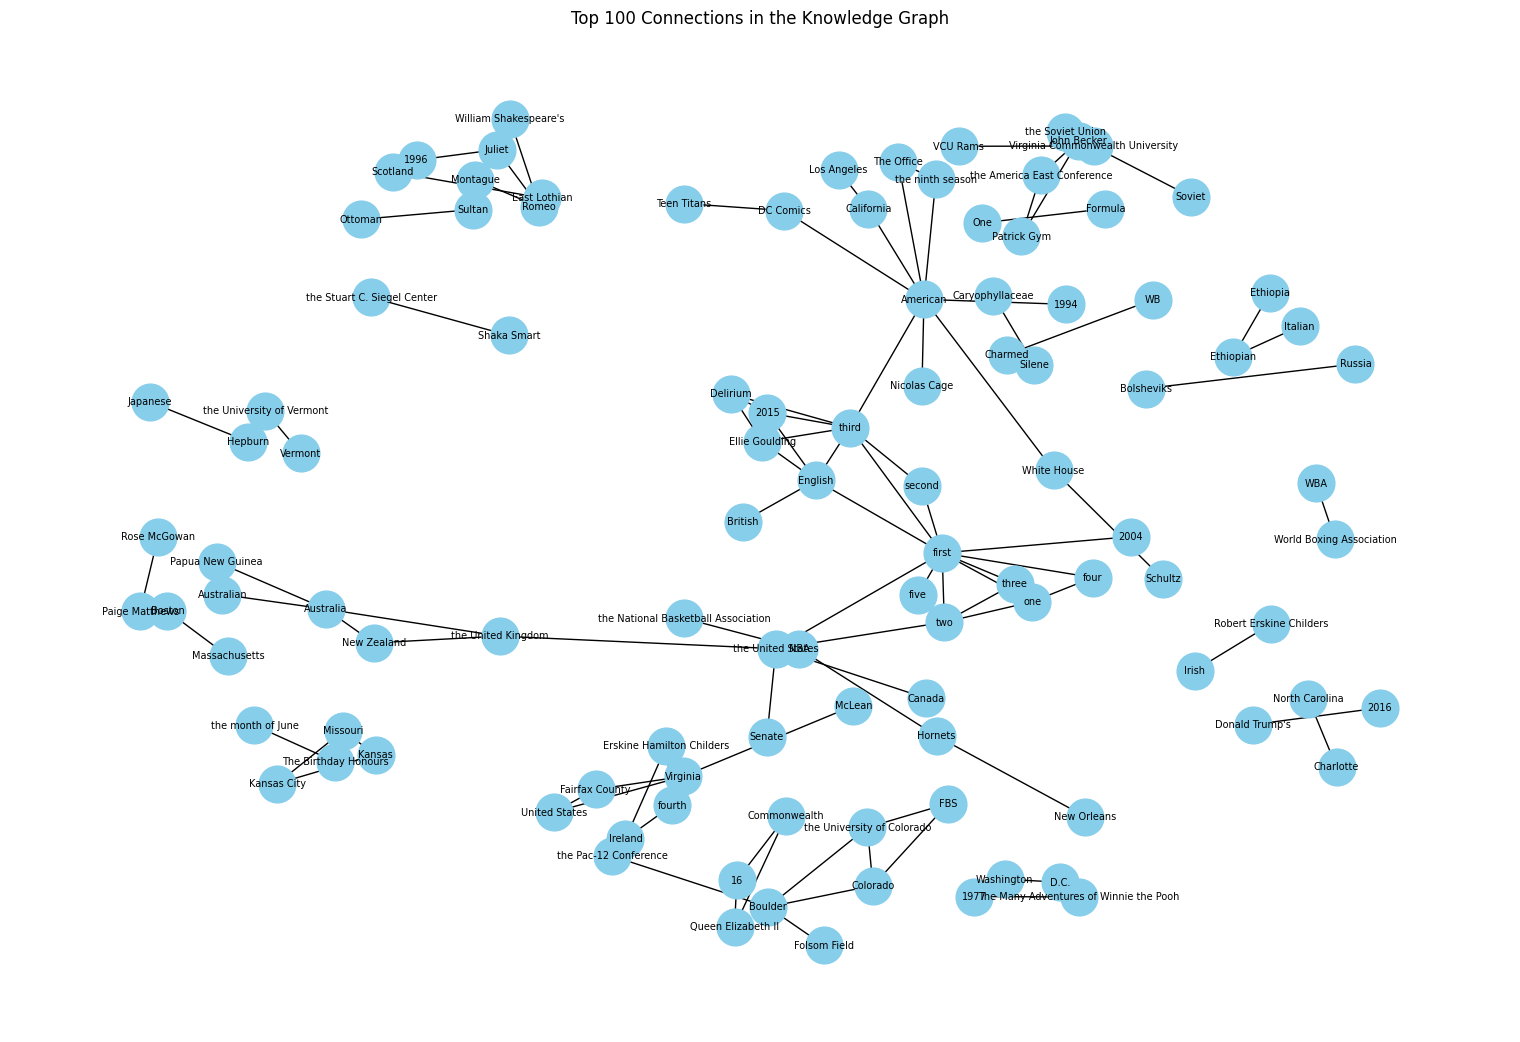

In [18]:
import matplotlib.pyplot as plt

top_100_edges = top_edges[:100]

G_small = nx.Graph()

for source, target, data in top_100_edges:
    G_small.add_edge(source, target, weight=data["weight"])

plt.figure(figsize=(15, 10))

pos = nx.spring_layout(G_small, seed=42, k=0.5)

nx.draw(
    G_small,
    pos,
    with_labels=True,
    node_size=700,
    font_size=7,
    width=1,
    node_color="skyblue"
)

plt.title("Top 100 Connections in the Knowledge Graph")
plt.show()

In [20]:
!pip install -q sentence-transformers faiss-cpu